# A practical guide to FOXES outputs

**Start with the question, then choose the output.** This tutorial uses a
reproducible wind-farm case to inspect performance, summarize farms and
clusters, sample the flow, create figures and write files.

| Your question | Class name | Model book entry |
| --- | --- | --- |
| What did each turbine produce? | `FarmResultsOutput` | `farm_results` |
| What are capacity factor and efficiency? | `FarmResultsOutput` | `farm_results_analysis` |
| What is the weighted whole-site summary? | `FarmResultsOutput` | `total_results_analysis_mean` |
| What is the wind at supplied points? | `PointResultsOutput` | `point_results` |
| Can an output configure its own probes? | `PointCalculator` | `point_calculator` |
| Where are the turbines? | `FarmLayoutOutput` | `farm_layout` |
| Where does the wind come from? | `RosePlotOutput` | `rose_plot` |
| What does a flow slice look like? | `SliceData`, `FlowPlots2D` | `slice_data`, `flow_plot_xy_mean` |
| Can I animate flow and turbine performance? | `FlowAnimation`, `FlowTurbineAnimation` | `create_gif`, `create_turbine_gif` |
| How do I write bounded-size NetCDF files? | `FarmResultsCountWriter`, `PointResultsCountWriter` | `farm_results_write_n1000`, `point_results_write_n1000` |

Run the cells in order. The main case contains **2,400 hourly timestamps
(100 days), 12 turbines and the public packaged NREL 5 MW curve**. No downloads,
measured operating data or private files are needed. All 2,400 timestamps
participate in the farm summaries and point profiles. High-resolution flow
examples explicitly select fewer timestamps rather than reducing grid quality.
Writers and GIF examples use temporary directories and embed their results.

Every public class exported by `foxes.models.outputs` has a runnable example,
including the `Animator` helper. The final **complete reference table** lists
every model-book preset and factory template, not just the shortcuts above.
This synthetic climate illustrates the APIs; it is not a measured energy
assessment or a production forecast.


## Read this first: three algorithm entry points, one output interface

**Choose the calculation entry point separately from the output class.**
All three methods accept `outputs=` as a model-book name, an output
instance, or a list mixing the two.

| Entry point | Inputs and scientific work | How outputs participate |
| --- | --- | --- |
| **`algo.calc_farm(outputs=...)`** | Calculates turbine/farm physics from the configured states and turbines. | Runs outputs on the calculated chunks. Point-dependent outputs can request grids or probes, evaluated in bounded point blocks within farm chunks. |
| **`algo.calc_points(farm_results, points=..., outputs=...)`** | Calculates the flow at the **supplied** coordinates. Waked calculations need sufficient farm fields; `ambient=True` permits no farm results. Alternatively supply `point_results=` to skip point physics. | Runs point results, writers or other compatible outputs. It **ignores** an output's `get_calc_points` request: the caller's points or precomputed point results determine the locations. |
| **`algo.calc_outputs(outputs=..., farm_results=..., point_results=...)`** | Reuses the supplied datasets. An output that requests points may still trigger new point physics. Missing farm inputs can trigger a farm calculation; with no supplied results, this is **not** a guarantee of post-processing-only execution. | Runs the chosen outputs without rerunning physics already supplied. Precomputed point results take precedence over requested grids and skip scientific point recalculation. |

**Important:** `calc_outputs` means "run these outputs", not "never run
science". Supply `farm_results` to avoid recalculating the farm, and
supply `point_results` as well when the point physics has already been
calculated. Supplied datasets must contain the fields needed by the next
calculation/output; missing performance metrics are not synthesized by
post-processing.

For follow-up waked point calculations, the named **`farm_results_calc`**
field set keeps standard scientific inputs, including thrust coefficient
and turbine geometry. It is different from the finite, user-facing
`farm_results` default. `farm_results_all` keeps every available field.
For newly requested points, `calc_outputs` merges the `calc` set with
explicit output farm-field requirements; `None` retains every available
field. Intermediate farm runs honor `states_sel`, including alignment of
state-dependent point coordinates. Declare model-specific extra fields
explicitly. With precomputed points, only explicit nonempty farm-field
requirements trigger missing farm calculations; numerical point-only
reuse stays science-free. Outputs needing neither farm fields nor point
science ignore supplied farm data and use the metadata-only lifecycle.

### Return values are a separate choice

**Use `ret_dict=True` when you want stable result-name keys.** Otherwise,
one selected output producing one value returns that value directly.
Multiple outputs return a mapping; writers and suppressed images may add
no collected value. Keys describe results, not necessarily the model-book
selector: for example `total_results_analysis_mean` produces
`FC.MEAN_TOTAL_FARM_RESULTS`.


## 1. Set up a 2,400-hour, 12-turbine calculation

Choose a Python environment containing FOXES. In a checkout, the test extra
provides notebook execution support (`uv sync --extra test`). Free scientific
design is used throughout: readable axes, physical units and explicit
interpretation, without a corporate style requirement.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import inspect
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Image, display
from PIL import Image as PillowImage

import foxes
import foxes.constants as FC
import foxes.variables as FV
from foxes.models import outputs

/home/jonas/gits/wakes/foxes/foxes/input/states/create/wrf2foxes.py:5: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm


In [2]:
n_timestamps = 2400
hours = np.arange(n_timestamps)
weather = pd.DataFrame(
    {
        FV.WS: 9.0
        + 2.0 * np.sin(2 * np.pi * hours / 24)
        + 1.2 * np.sin(2 * np.pi * hours / 168),
        FV.WD: np.where((hours // 72) % 3 == 2, 90.0, 270.0)
        + 12.0 * np.sin(2 * np.pi * hours / 48),
        FV.WEIGHT: np.full(n_timestamps, 1.0 / n_timestamps),
    },
    index=pd.date_range("2020-01-01", periods=n_timestamps, freq="h"),
)
states = foxes.input.states.StatesTable(
    weather,
    output_vars=[FV.WS, FV.WD, FV.TI, FV.RHO],
    fixed_vars={FV.TI: 0.08, FV.RHO: 1.225},
)
display(
    weather.head(8).rename(
        columns={FV.WS: "Wind speed [m/s]", FV.WD: "Direction [deg]"}
    )
)
display(
    pd.Series(
        {
            "timestamps": len(weather),
            "first": weather.index[0],
            "last": weather.index[-1],
        }
    )
)
assert len(weather) >= 2000
assert np.isclose(weather[FV.WEIGHT].sum(), 1.0)

,Wind speed [m/s],Direction [deg],weight
2020-01-01 00:00:00,9.000000,270.000000,0.000417
2020-01-01 01:00:00,9.562508,271.566314,0.000417
2020-01-01 02:00:00,10.089676,273.105829,0.000417
2020-01-01 03:00:00,10.548571,274.592201,0.000417
2020-01-01 04:00:00,10.910902,276.000000,0.000417
2020-01-01 05:00:00,11.154946,277.305137,0.000417
2020-01-01 06:00:00,11.267025,278.485281,0.000417
2020-01-01 07:00:00,11.242435,279.520240,0.000417


timestamps                   2400
first         2020-01-01 00:00:00
last          2020-04-09 23:00:00
dtype: object

The hourly samples have equal probability; their weights sum to one.
Calendar timestamps also make count and calendar writer policies easy to
compare. Wind directions are meteorological: 270 degrees is wind **from the
west**, and 90 degrees is from the east.

Twelve turbines form three rows of four. The named wind farms are South,
Central and North; the Lower cluster contains the first two rows and the
Upper cluster the last row. Membership is explicit, not inferred from position.


In [3]:
farm = foxes.WindFarm()
memberships = [
    (
        (600.0 * column, 700.0 * row),
        ("South", "Central", "North")[row],
        "Lower" if row < 2 else "Upper",
    )
    for row in range(3)
    for column in range(4)
]
for index, (xy, wind_farm, cluster) in enumerate(memberships):
    farm.add_turbine(
        foxes.Turbine(
            xy,
            name=f"T{index + 1:02d}",
            turbine_models=["NREL5MW"],
            wind_farm_name=wind_farm,
            cluster_name=cluster,
        ),
        verbosity=0,
    )

algo = foxes.algorithms.Downwind(
    farm, states, rotor_model="centre", wake_models=["Jensen_linear_k004"], verbosity=0
)
engine = foxes.Engine.new(
    "numpy", n_procs=1, chunk_size_states=128, chunk_size_points=2048, verbosity=0
)
assert farm.n_turbines >= 10

## 2. Calculate farm results and performance metrics

This first **`calc_farm`** call runs all 2,400 timestamps and 12 turbines.
Its `outputs` list collects all available farm fields and a state-mean
performance dataset in one scientific run. Keeping all available fields is
convenient for the diverse follow-up examples; choose `farm_results_calc`
plus any additional required fields when that smaller selection is sufficient.

**Derived variables are evaluated automatically when requested. Do not add a
`TurbineEvaluation` turbine model manually.** An output configured only with
`variables=None` does not itself request new derived metrics.


In [4]:
metrics = [FV.P, FV.AMB_P, FV.CAP, FV.AMB_CAPF, FV.CAPF, FV.EFF, FV.YLD]
with engine:
    results = algo.calc_farm(
        outputs=[
            "farm_results_all",
            outputs.FarmResultsOutput(variables=metrics, aggregate_states=True),
        ],
        ret_dict=True,
    )

farm_results = results[FC.FARM_RESULTS]
performance = farm_results
display(pd.DataFrame({name: dict(data.sizes) for name, data in results.items()}).T)
display(
    performance.isel({FC.STATE: 0})
    .to_dataframe()[[FV.P, FV.AMB_P, FV.CAPF, FV.EFF, FV.YLD]]
    .round(3)
)
assert farm_results.sizes[FC.STATE] == n_timestamps
assert farm_results.sizes[FC.TURBINE] == 12
assert all(variable in farm_results for variable in metrics)

,state,turbine
farm_results,2400.0,12.0
mean_farm_results,NaN,12.0


,P,AMB_P,CAPF,EFF,YLD
turbine,,,,,
0,2518.600,2518.6,0.504,1.000,22.063
1,936.912,2518.6,0.187,0.372,8.207
2,541.140,2518.6,0.108,0.215,4.740
3,359.655,2518.6,0.072,0.143,3.151
4,2518.600,2518.6,0.504,1.000,22.063
5,936.912,2518.6,0.187,0.372,8.207
6,541.140,2518.6,0.108,0.215,4.740
7,359.655,2518.6,0.072,0.143,3.151
8,2518.600,2518.6,0.504,1.000,22.063


For this turbine type, `P`, `AMB_P` and `CAP` are in **kW**. Power units follow the turbine type; they are not universally kW. `AMB_P` is the no-wake reference power. `CAPF = P / CAP`, `AMB_CAPF = AMB_P / CAP` and `EFF = P / AMB_P` are **fractions**, not percentages.

`YLD` is in **GWh/a**: each state initially stores the yield obtained by annualizing that state's power for 8,760 hours. It is **not yet a probability-weighted contribution**. Use state aggregation to obtain a climate-weighted annual estimate. Requesting `P75`/`P90` additionally requires an explicit power uncertainty; this introductory example does not assume one.

The table above shows the first westerly condition. Turbines behind other turbines lose power relative to `AMB_P`. Result indices retain the original farm order, even when the wind reverses.

## 3. Summarize turbines, wind farms, clusters or the whole site

State and spatial aggregation are independent:

- `aggregate_states=True` uses normalized state probabilities separately for each entity.
- `aggregate_turbines=None` keeps turbines; `"wind_farm"`, `"cluster"` and `"all"` select spatial groups.
- Power, capacity and yield **sum** across turbines. Intensive fields **average**, directions use circular means, and ratios are recomputed from aggregated power/capacity.

This is why a plain `.mean()` over every dimension is not a suitable farm summary. The following summaries reuse `farm_results`; the turbine physics is not rerun.

In [5]:
groups = {
    FC.MEAN_FARM_RESULTS: None,
    FC.MEAN_FARMS_RESULTS: "wind_farm",
    FC.MEAN_CLUSTER_RESULTS: "cluster",
    FC.MEAN_TOTAL_FARM_RESULTS: "all",
}
with engine:
    summaries = algo.calc_outputs(
        farm_results=farm_results,
        outputs=[
            outputs.FarmResultsOutput(
                variables=metrics,
                aggregate_turbines=group,
                aggregate_states=True,
            )
            for group in groups.values()
        ],
    )

display(summaries[FC.MEAN_FARMS_RESULTS].to_dataframe()[metrics].round(3))
display(
    pd.DataFrame(
        [
            {"output": name, "dimensions": dict(data.sizes), **data.attrs}
            for name, data in summaries.items()
        ]
    ).set_index("output")
)
expected_power = np.average(performance[FV.P], axis=0, weights=weather[FV.WEIGHT])
assert np.isclose(
    summaries[FC.MEAN_TOTAL_FARM_RESULTS][FV.P].item(), expected_power.sum()
)

,P,AMB_P,CAP,AMB_CAPF,CAPF,EFF,YLD
wind_farm,,,,,,,
South,8054.19,10861.511,20000.0,0.543,0.403,0.742,70.555
Central,8054.19,10861.511,20000.0,0.543,0.403,0.742,70.555
North,8054.19,10861.511,20000.0,0.543,0.403,0.742,70.555


,dimensions,power_unit,n_states,aggregate_states,n_turbines,aggregate_turbines
output,,,,,,
mean_farm_results,{'turbine': 12},kW,2400,1,NaN,NaN
mean_farms_results,{'wind_farm': 3},kW,2400,1,12.0,wind_farm
mean_cluster_results,{'cluster': 2},kW,2400,1,12.0,cluster
mean_total_farm_results,{},kW,2400,1,12.0,all


The reduced dataset's `n_states` and `n_turbines` attributes count input
entities, not the remaining dimension sizes. Counts appear for eliminated
axes; a per-turbine mean still has its turbine dimension.

### Select timestamps before calculating a mean

`states_sel` takes state **labels**, not integer positions. Here we retain
the first 24 hourly samples. Their weights sum to 0.01; aggregation
renormalizes them, so the result describes the first day rather than one
percent of the whole-case result.


In [6]:
selected_states = list(weather.index[:24])
with engine:
    selected_mean = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=selected_states,
        outputs=outputs.FarmResultsOutput(
            variables=metrics, aggregate_turbines="all", aggregate_states=True
        ),
    )

display(pd.Series({variable: selected_mean[variable].item() for variable in metrics}))
display(selected_mean.attrs)
assert selected_mean.attrs["n_states"] == len(selected_states)

P           27088.810783
AMB_P       36797.251053
CAP         60000.000000
AMB_CAPF        0.613288
CAPF            0.451480
EFF             0.736164
YLD           237.297982
dtype: float64

{'power_unit': 'kW',
 'n_states': 24,
 'n_turbines': 12,
 'aggregate_turbines': 'all',
 'aggregate_states': 1}

### Quick outputs with model-book shortcuts

Pass a model-book name directly as `outputs="..."` instead of constructing an output model. `calc_farm`, `calc_outputs` and `calc_points` accept these shortcuts; lists can mix names and instances.

| Shortcut | Quick result |
| --- | --- |
| `farm_results` | Ordinary fields for each state and turbine |
| `farm_results_calc` | Standard inputs for subsequent waked point calculations |
| `farm_results_P_mean` | Weighted ambient/waked mean power per turbine |
| `farms_results` | One result per state and wind farm |
| `cluster_results_mean` | Weighted summary per cluster |
| `total_results` | One whole-site result per state, combining all turbines |
| `total_results_analysis_mean` | Whole-site capacity, capacity factors and efficiency |
| `point_results_mean` | Weighted wind fields at each supplied point |
| `total_results_write_n4` | Whole-site NetCDF files with at most four input states each |
| `point_results_write_day` | One NetCDF file per calendar day |

All three spatially grouped farm families are available as plain names: `farms_results`, `cluster_results` and `total_results`. This table resolves actual presets without running another simulation:

In [7]:
preset_names = [
    "farm_results",
    "farm_results_calc",
    "farm_results_analysis",
    "farms_results",
    "cluster_results",
    "total_results",
    "total_results_analysis_mean",
    "point_results_mean",
    "total_results_write_n4",
    "point_results_write_day",
]
display(
    pd.DataFrame(
        [
            {"preset": name, "class": type(algo.mbook.outputs[name]).__name__}
            for name in preset_names
        ]
    ).set_index("preset")
)

,class
preset,
farm_results,FarmResultsOutput
farm_results_calc,FarmResultsOutput
farm_results_analysis,FarmResultsOutput
farms_results,FarmResultsOutput
cluster_results,FarmResultsOutput
total_results,FarmResultsOutput
total_results_analysis_mean,FarmResultsOutput
point_results_mean,PointResultsOutput
total_results_write_n4,FarmResultsCountWriter


#### Run one shortcut, or combine several

For a new calculation, use `algo.calc_farm(outputs="total_results_analysis_mean")` inside the engine context. Selecting `analysis` requests the derived metrics automatically; no evaluation turbine model is needed.

Both calls below reuse our earlier `farm_results` through `calc_outputs` without recalculating turbine physics. Reused data must already contain the requested fields: `calc_outputs` does not calculate missing turbine metrics. We requested the `analysis` metrics, including `AMB_CAPF`, in our original calculation. By default, one results class returns its dataset directly. Several results classes return a mapping keyed by their **dataset keys**, not their model-book names: `farm_results_P_mean` uses `FC.MEAN_FARM_RESULTS`, while `total_results_P_mean` uses `FC.MEAN_TOTAL_FARM_RESULTS`. Set `ret_dict=True` when a mapping is also needed for a single selection.

In [8]:
with engine:
    quick_total = algo.calc_outputs(
        farm_results=farm_results,
        outputs="total_results_analysis_mean",
    )
    quick_outputs = algo.calc_outputs(
        farm_results=farm_results,
        outputs=["farm_results_P_mean", "total_results_P_mean"],
    )
display(quick_total)
display(quick_outputs[FC.MEAN_FARM_RESULTS])
display(quick_outputs[FC.MEAN_TOTAL_FARM_RESULTS])

<xarray.Dataset> Size: 40B
Dimensions:   ()
Data variables:
    CAP       float64 8B 6e+04
    AMB_CAPF  float64 8B 0.5431
    CAPF      float64 8B 0.4027
    EFF       float64 8B 0.7415
    weight    float64 8B 1.0
Attributes:
    power_unit:          kW
    n_states:            2400
    n_turbines:          12
    aggregate_turbines:  all
    aggregate_states:    1

<xarray.Dataset> Size: 1kB
Dimensions:    (turbine: 12)
Coordinates:
  * turbine    (turbine) int64 96B 0 1 2 3 4 5 6 7 8 9 10 11
Data variables:
    AMB_P      (turbine) float64 96B 2.715e+03 2.715e+03 ... 2.715e+03 2.715e+03
    P          (turbine) float64 96B 2.384e+03 1.839e+03 ... 1.792e+03 2.039e+03
    weight     (turbine) float64 96B 1.0 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0 1.0
    tname      (turbine) <U3 144B 'T01' 'T02' 'T03' 'T04' ... 'T10' 'T11' 'T12'
    wind_farm  (turbine) <U7 336B 'South' 'South' 'South' ... 'North' 'North'
    cluster    (turbine) <U5 240B 'Lower' 'Lower' 'Lower' ... 'Upper' 'Upper'
Attributes:
    power_unit:        kW
    n_states:          2400
    aggregate_states:  1

<xarray.Dataset> Size: 24B
Dimensions:  ()
Data variables:
    AMB_P    float64 8B 3.258e+04
    P        float64 8B 2.416e+04
    weight   float64 8B 1.0
Attributes:
    power_unit:          kW
    n_states:            2400
    n_turbines:          12
    aggregate_turbines:  all
    aggregate_states:    1

#### Build a shortcut and find available names

For farm outputs the order is `<family>[_amb|_waked][_<fields>][_mean]`, then an optional writer suffix:

- **Family:** `farm_results`, `farms_results`, `cluster_results` or `total_results` chooses the turbine grouping.
- **Filter:** `_amb` or `_waked` selects one side of the ambient/waked fields; omit it for both.
- **Fields:** `_calc` retains standard point-calculation inputs; `_P` selects ambient/waked power and weights; `_wsP` adds rotor-effective wind speed. `_analysis` requests capacity, capacity factors and efficiency. `_all` retains available fields; it does not request every derived metric.
- **Mean:** `_mean` reduces the selected states using normalized weights. Omit it to keep states. Extensive fields still sum across turbines, and ratios are recomputed.
- **Writer:** `_write_n4`, `_write_chunks` or `_write_day` / `_week` / `_month` / `_year` chooses files instead of a collected dataset. For example, `total_results_waked_P_mean_write_month` writes monthly weighted whole-site power. Count/calendar means are computed separately for each file's input states. Chunk files follow engine chunks.

`farm_results_all` means **all available fields per turbine**; `total_results` means **all turbines combined**; `total_results_all` does both. Point shortcuts follow the same order, but use `point_results` and optionally `_aggregate_all` before `_mean` to average across points.

Discover presets and factory patterns with `algo.mbook.print_toc(subset=["outputs"], search="total_results")`. Resolve one with `algo.mbook.outputs[name]` to inspect or configure it **before** running, or use an explicit constructor for custom fields, filenames or axes. Writers produce files, not a dataset; combine a writer and results class when you need both. See the writing section below for temporary-directory recipes.

## 4. Check the layout and wind climate

Use constructor-defined plot outputs with existing data. The layout below makes it clear which turbines can sit in each other's wakes. A wind rose shows **weighted frequencies**, not the number of input rows.

Output constructors default to `show=False`. We display figures explicitly with Matplotlib in the notebook. Static plotting **presets** instead enable blocking display, so use instances or set their `show` flag to false for headless scripts.

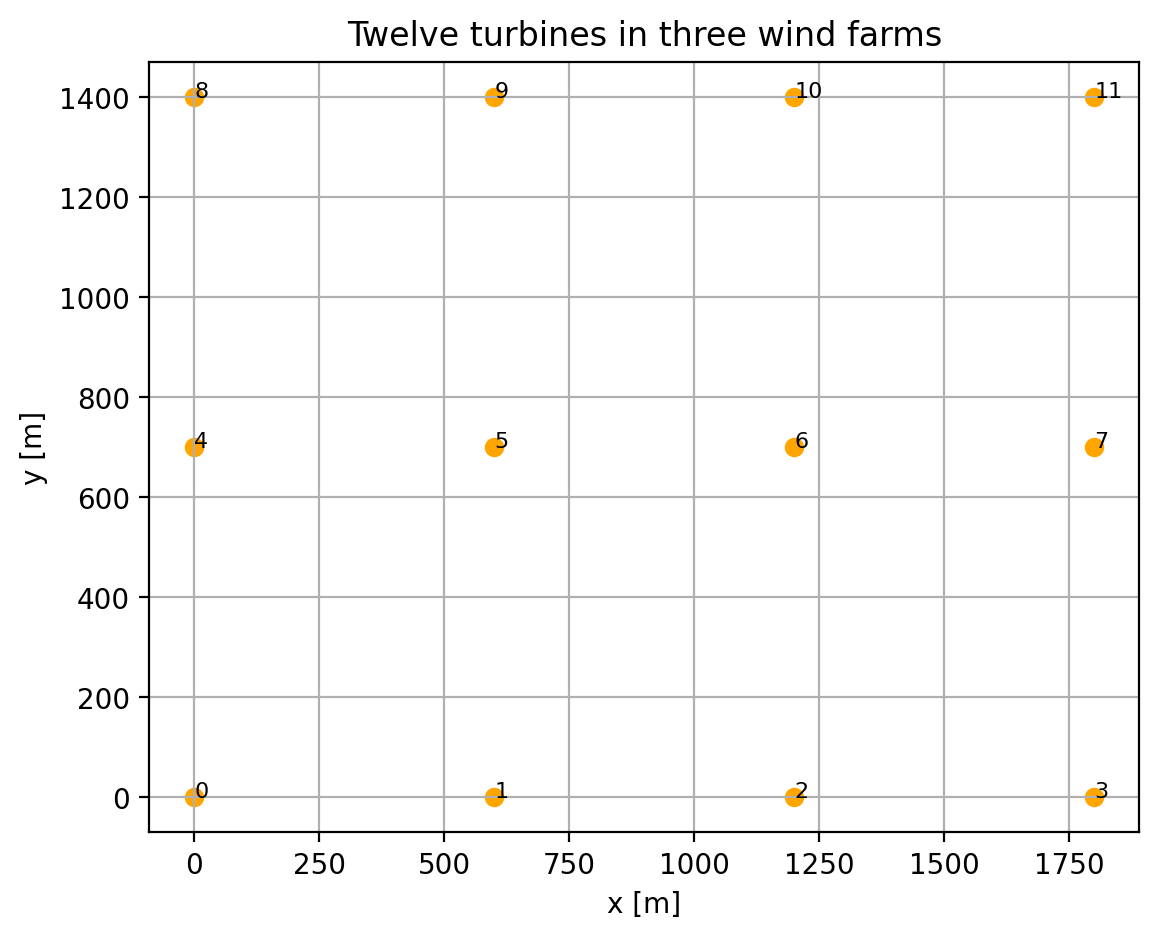

In [9]:
with engine:
    layout = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.FarmLayoutOutput(
            operation="get_figure",
            parameters={
                "figsize": (10, 5),
                "annotate": 1,
                "title": "Twelve turbines in three wind farms",
            },
        ),
    )
plt.show()
plt.close("all")

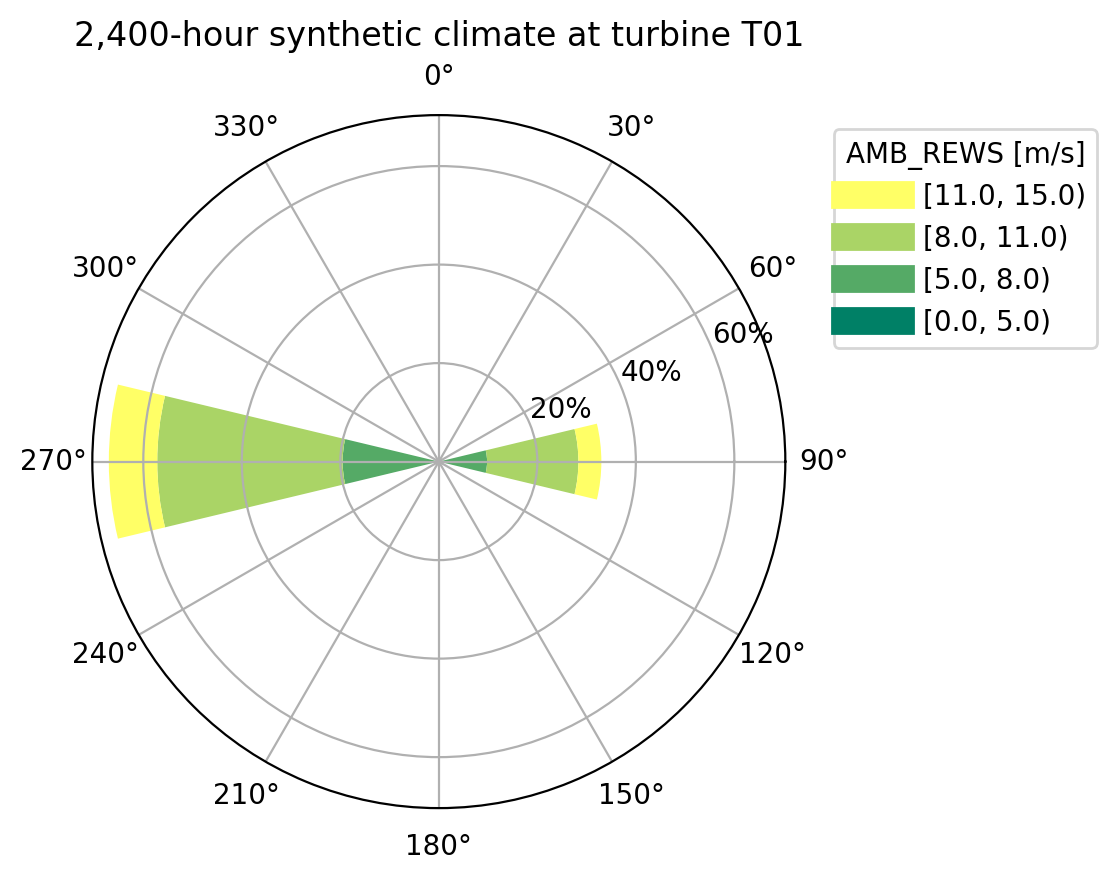

In [10]:
with engine:
    rose_axes, rose_data = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.RosePlotOutput(
            wd_sectors=12,
            ws_bins=[0, 5, 8, 11, 15],
            plot_pars={
                "figsize": (6, 4.5),
                "freq_delta": 20,
                "title": "2,400-hour synthetic climate at turbine T01",
                "legend_pars": {"bbox_to_anchor": (1.05, 1), "loc": "upper left"},
            },
        ),
    )
plt.show()
plt.close("all")

### Ambient roses and power within wind bins

`StatesRosePlotOutput` samples ambient states at one explicitly configured
location; `ambient=True` avoids wakes in this point evaluation.
`WindRoseBinPlot` instead summarizes a field within wind-speed/direction
bins. The numerical example below reports **weighted mean power in kW**,
not occurrence percentages. Both use the complete 2,400-hour case.


P
AMB_WD AMB_REWS             
90.0   6.5        729.636225
       9.5       1731.661501
       13.0      3590.504310
270.0  6.5       1239.015466
       9.5       2948.649375
       13.0      4801.629653

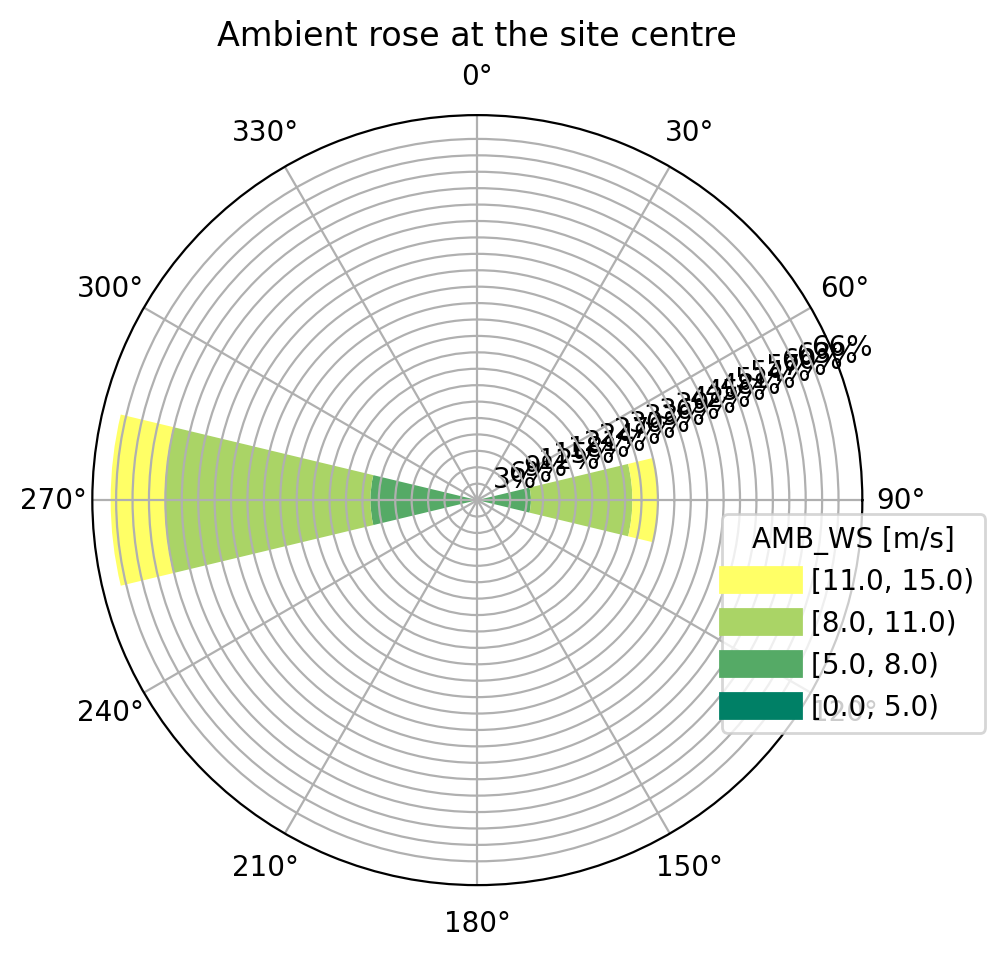

In [11]:
with engine:
    ambient_rose = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.StatesRosePlotOutput(
            point=(900.0, 700.0, 90.0),
            ws_bins=[0, 5, 8, 11, 15],
            plot_pars={"figsize": (7, 5), "title": "Ambient rose at the site centre"},
        ),
        ambient=True,
    )
    binned_power = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.WindRoseBinPlot(
            variable=FV.P, ws_bins=[0, 5, 8, 11, 15], plot=False
        ),
    )
display(binned_power.to_dataframe().dropna().head(8))
plt.show()
plt.close("all")

### Native support-point histograms

`SupportWindRosePlotOutput` is for **binned states**, not an ordinary
`StatesTable`. This explicit auxiliary algorithm bins the same synthetic
hourly weather at two support points, then renders their native
histograms. Spatially uniform input produces identical roses at both
points. The state reduction is an initialization calculation, not an
interpolation performed by the plotting output.


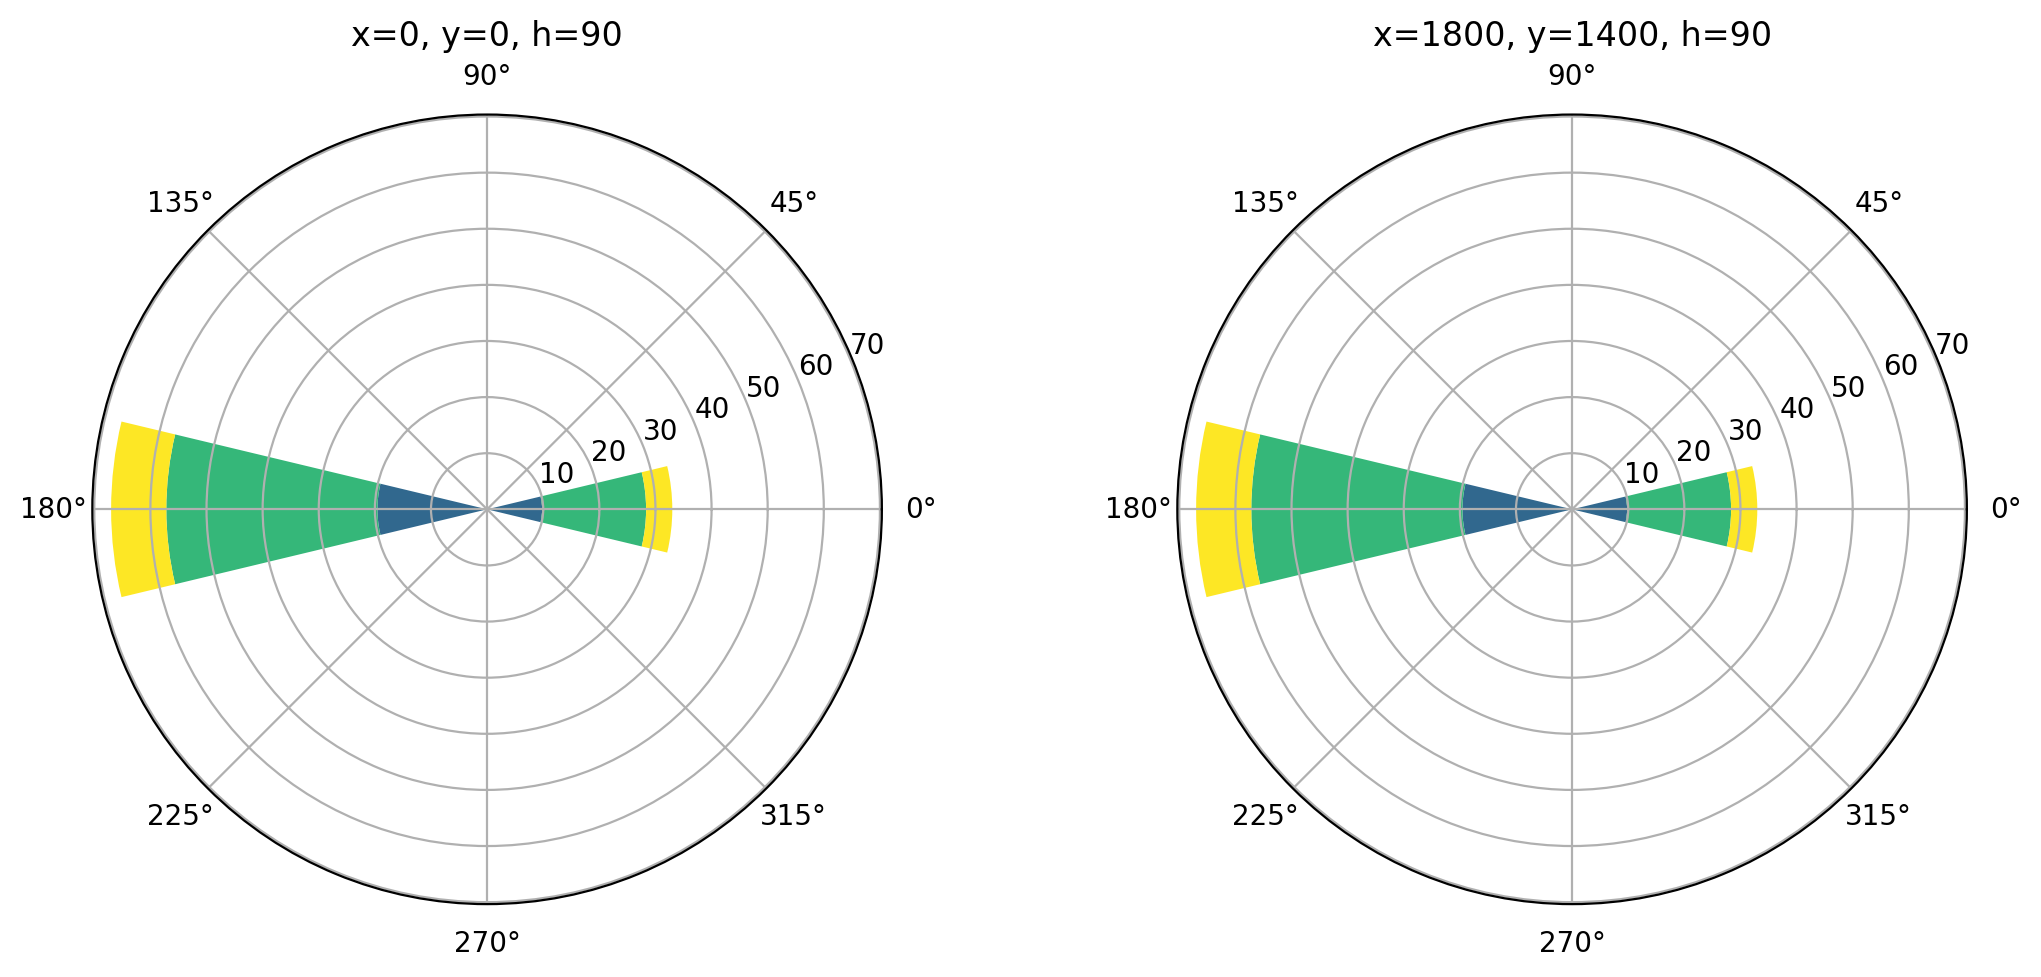

In [12]:
support_source = foxes.input.states.StatesTable(
    weather,
    output_vars=[FV.WS, FV.WD, FV.TI, FV.RHO],
    fixed_vars={FV.TI: 0.08, FV.RHO: 1.225},
)
binned_states = foxes.input.states.BinnedPointCloudData(
    support_source,
    bin_vars={FV.WS: [0, 5, 8, 11, 15], FV.WD: 12},
    support_points=np.array([[0.0, 0.0, 90.0], [1800.0, 1400.0, 90.0]]),
    interpolation="nearest",
)
support_algo = foxes.algorithms.Downwind(
    farm, binned_states, wake_models=[], verbosity=0
)
with engine:
    support_results = support_algo.calc_outputs(
        outputs=outputs.SupportWindRosePlotOutput(
            plot_pars={"ncols": 2, "figsize": (11, 5)}
        ),
        ret_dict=True,
    )
support_figure, support_data = support_results["support_rose_plot"]
np.testing.assert_allclose(support_data.frequency.sum((FV.WD, FV.WS)), 100.0)
plt.show()
plt.close("all")

Westerly conditions dominate this synthetic climate, but easterly conditions reverse the upstream/downstream ordering. The physical aggregation above accounts for all conditions rather than selecting one layout ordering.

## 5. Sample the flow along a line

`calc_points` accepts static coordinates shaped `(n_points, 3)` in metres, or state-dependent coordinates shaped `(n_states, n_points, 3)`. Point results use `(state, point)` dimensions and retain location coordinates.

`PointResultsOutput` mirrors `FarmResultsOutput`: `aggregate_states=True` creates a weighted state mean, while `aggregate_points="all"` averages locations. This example keeps the locations so we can draw a profile.

,state,point
point_results,2400.0,80.0
mean_point_results,NaN,80.0


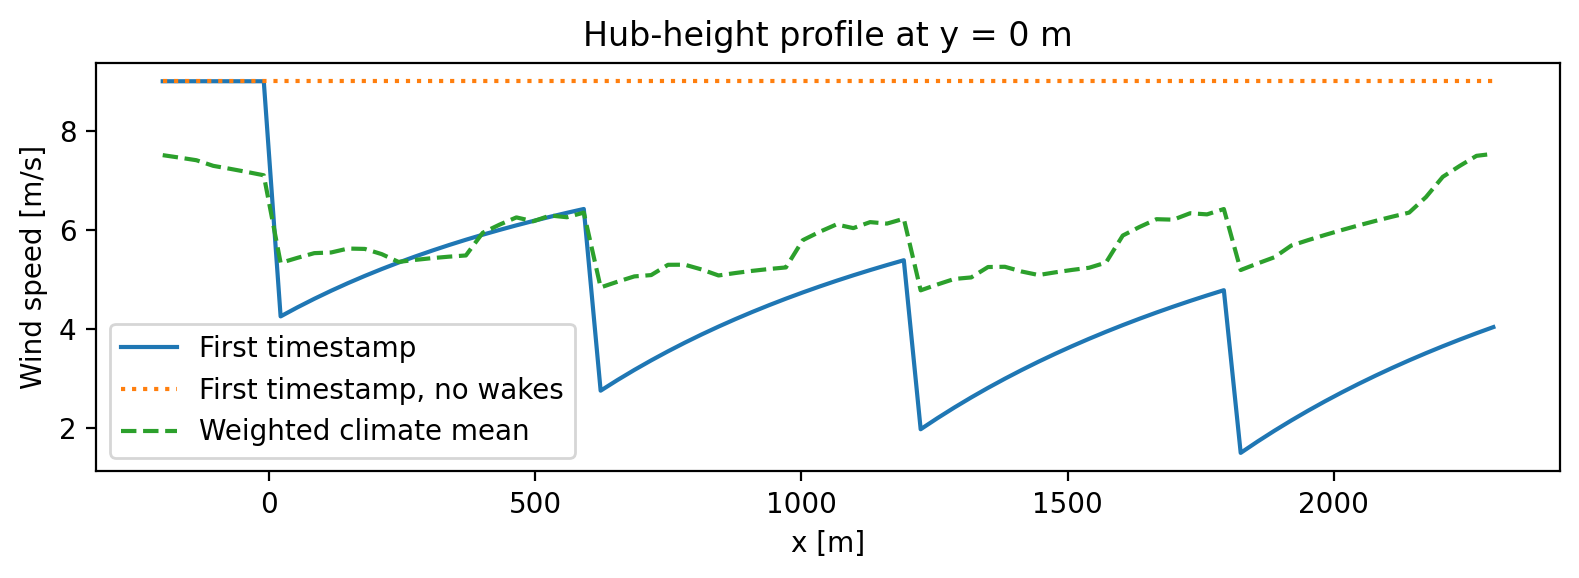

In [13]:
points = np.column_stack(
    [np.linspace(-200.0, 2300.0, 80), np.zeros(80), np.full(80, 90.0)]
)
with engine:
    point_outputs = algo.calc_points(
        farm_results,
        points=points,
        outputs=[
            "point_results_all",
            outputs.PointResultsOutput(
                variables=[FV.WS, FV.AMB_WS],
                aggregate_states=True,
            ),
        ],
    )
point_results = point_outputs[FC.POINT_RESULTS]
mean_points = point_outputs[FC.MEAN_POINT_RESULTS]
display(
    pd.DataFrame({name: dict(data.sizes) for name, data in point_outputs.items()}).T
)
assert FC.STATE not in mean_points.dims

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(points[:, 0], point_results[FV.WS].isel({FC.STATE: 0}), label="First timestamp")
ax.plot(
    points[:, 0],
    point_results[FV.AMB_WS].isel({FC.STATE: 0}),
    label="First timestamp, no wakes",
    linestyle=":",
)
ax.plot(points[:, 0], mean_points[FV.WS], label="Weighted climate mean", linestyle="--")
ax.set(xlabel="x [m]", ylabel="Wind speed [m/s]", title="Hub-height profile at y = 0 m")
ax.legend()
fig.tight_layout()
plt.show()
plt.close("all")

### Let `PointCalculator` own the probe coordinates

Unlike `PointResultsOutput`, `PointCalculator` can configure its own
`points`. Calling it through `calc_outputs` therefore requests fresh
point physics even though the supplied farm results are reused. Here
eight probes reproduce the corresponding full-case mean profile above.


In [14]:
with engine:
    probe_means = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.PointCalculator(
            points=points[::10], variables=[FV.WS], states_mean=True
        ),
    )
np.testing.assert_allclose(probe_means[FV.WS], mean_points[FV.WS].values[::10])
display(probe_means.to_dataframe())

,WS,x,y,z
point,,,,
0,7.508851,-200.000000,0.0,90.0
1,5.544886,116.455696,0.0,90.0
2,6.106988,432.911392,0.0,90.0
3,5.296289,749.367089,0.0,90.0
4,6.110682,1065.822785,0.0,90.0
5,5.256092,1382.278481,0.0,90.0
6,6.206580,1698.734177,0.0,90.0
7,5.997184,2015.189873,0.0,90.0


The solid and dotted profiles compare wakes and ambient flow for the same
first timestamp. The dashed curve is the weighted mean of **all 2,400 hours**.

## 6. High-resolution slices and flow maps

`SliceData` returns numerical grids; `FlowPlots2D` creates figures.
Both support `xy`, `xz` and `yz` planes. Every flow field and animation below
uses a **240 x 160 grid (38,400 points per plane)** and a 12-inch-wide
figure. This resolves the 126-metre rotors with multiple cells rather than
using coarse thumbnail grids.

High spatial resolution is kept affordable by selecting timestamps **at the
algorithm entry point**. The numerical mean uses 24 explicitly selected
snapshots; the flow figure uses only the first timestamp. Neither is
presented as the full 2,400-hour climate mean.

`aggregate_states=True` normalizes the selected-state weights. Ordinary
`reduction="mean"` instead retains weighted-sum semantics.


In [15]:
grid = {
    "n_img_points": (240, 160),
    "xmin": -300.0,
    "xmax": 2400.0,
    "ymin": -300.0,
    "ymax": 1700.0,
    "z": 90.0,
}
flow_states = list(weather.index[::100])
animation_states = list(weather.index[[0, 6, 12, 18]])
with engine:
    mean_slice = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=flow_states,
        outputs=outputs.SliceData(
            plane="xy",
            variables=[FV.WS, FV.WD],
            aggregate_states=True,
            data_format="xarray",
            grid_pars=grid,
        ),
    )
display(mean_slice)
assert mean_slice.sizes["x"] == 240
assert mean_slice.sizes["y"] == 160
assert mean_slice.attrs["n_states"] == len(flow_states)

<xarray.Dataset> Size: 618kB
Dimensions:  (y: 160, x: 240)
Coordinates:
  * y        (y) float64 1kB -300.0 -287.4 -274.8 ... 1.687e+03 1.7e+03
  * x        (x) float64 2kB -300.0 -288.7 -277.4 ... 2.389e+03 2.4e+03
Data variables:
    WS       (y, x) float64 307kB 8.966 8.966 8.966 8.966 ... 8.966 8.966 8.966
    WD       (y, x) float64 307kB 267.4 267.4 267.4 267.4 ... 267.4 267.4 267.4
Attributes:
    z:                 90.0
    n_states:          24
    aggregate_states:  1

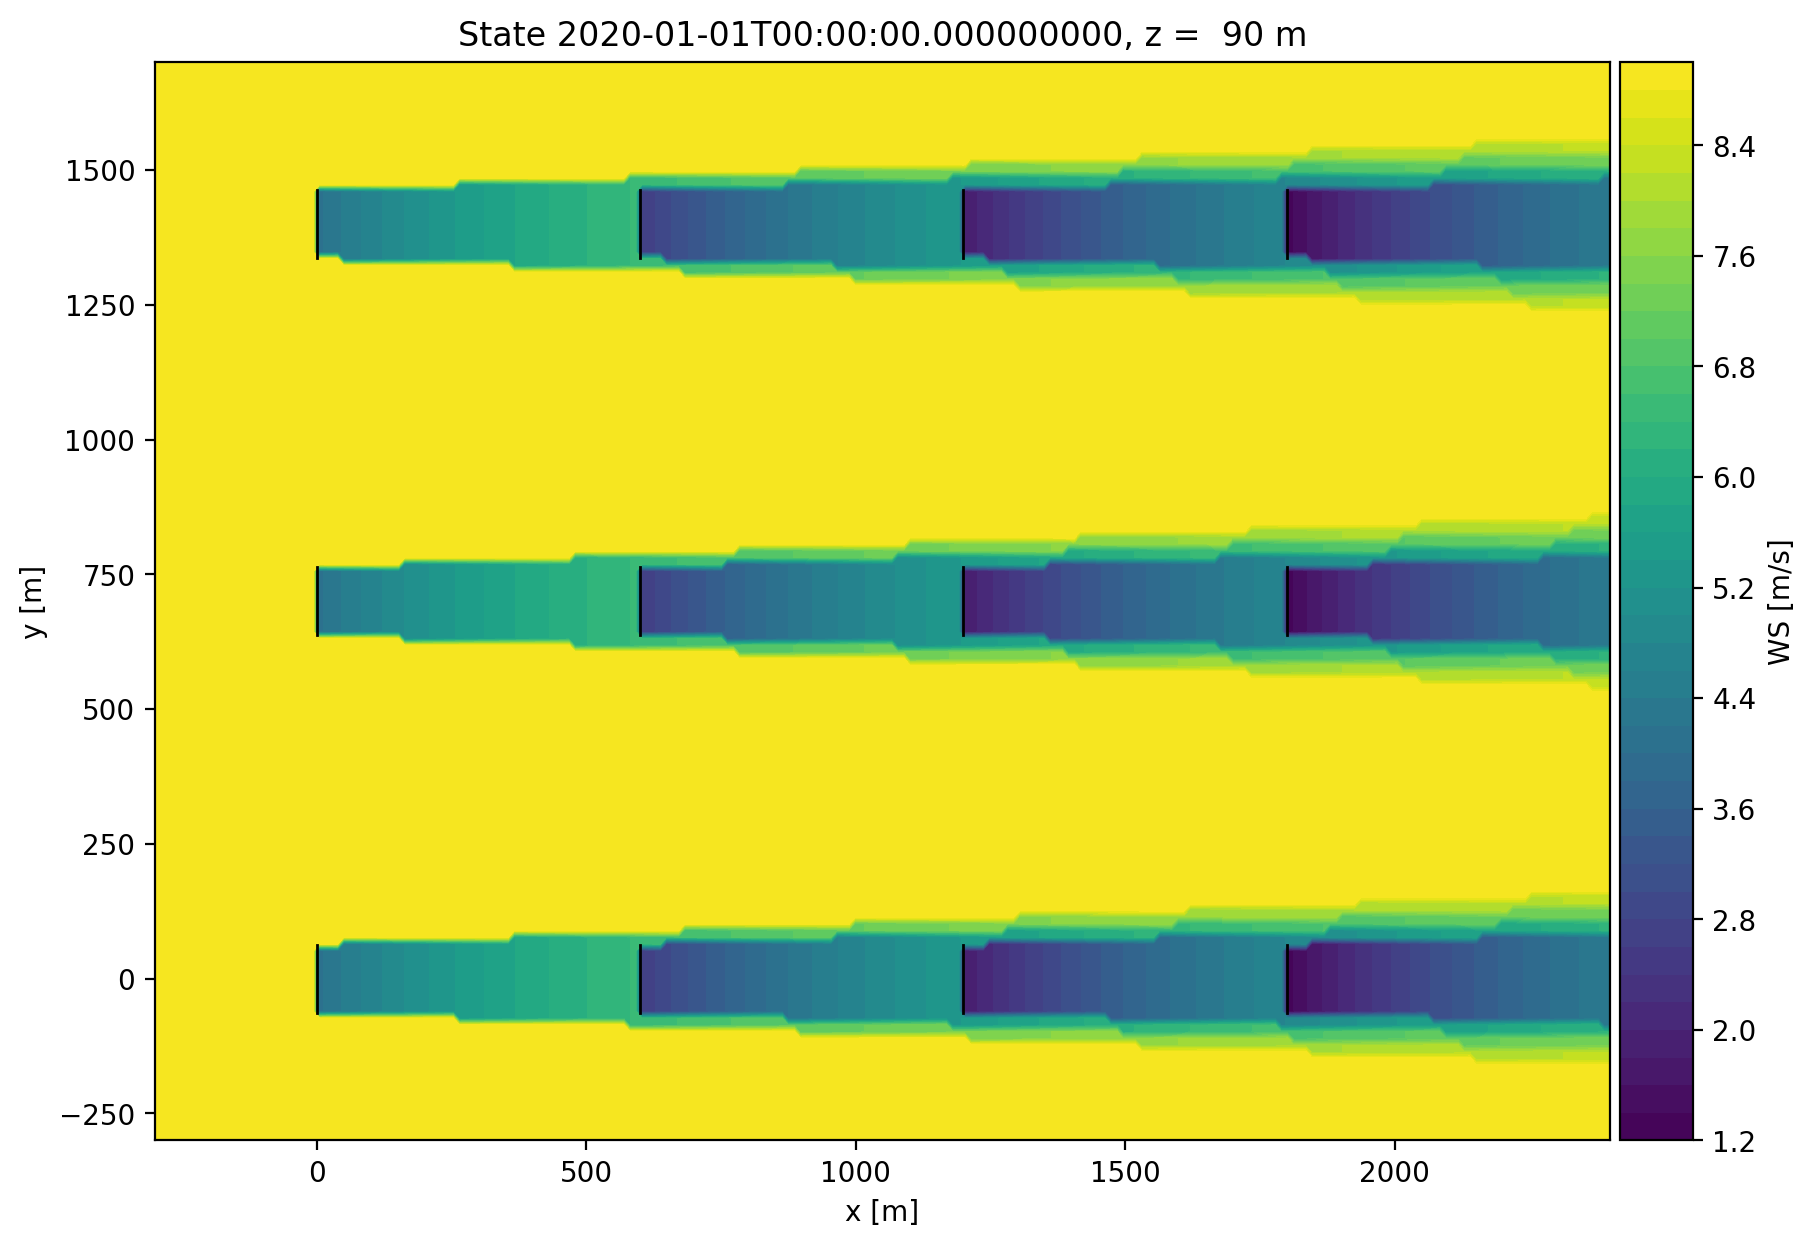

In [16]:
with engine:
    flow_figures = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=[weather.index[0]],
        outputs=outputs.FlowPlots2D(
            plane="xy",
            var=FV.WS,
            reduction="states",
            grid_pars=grid,
            plot_pars={"figsize": (12, 7), "levels": 40, "rotor_color": "black"},
        ),
    )
plt.show()
plt.close("all")

### Several parallel planes with `SlicesData`

One output requests three planes at 70, 90 and 110 metres and joins them
in a single dataset. The same 240 x 160 resolution is retained on every
plane; only one timestamp is evaluated here.


In [17]:
with engine:
    stacked_slices = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=[weather.index[0]],
        outputs=outputs.SlicesData(
            positions=[70.0, 90.0, 110.0],
            plane="xy",
            variables=[FV.WS],
            grid_pars=grid,
        ),
    )
display(stacked_slices)
assert stacked_slices.sizes["z"] == 3
assert stacked_slices.sizes["x"] == 240
assert stacked_slices.sizes["y"] == 160

<xarray.Dataset> Size: 925kB
Dimensions:  (z: 3, state: 1, y: 160, x: 240)
Coordinates:
  * state    (state) datetime64[ns] 8B 2020-01-01
  * y        (y) float64 1kB -300.0 -287.4 -274.8 ... 1.687e+03 1.7e+03
  * x        (x) float64 2kB -300.0 -288.7 -277.4 ... 2.389e+03 2.4e+03
  * z        (z) float64 24B 70.0 90.0 110.0
Data variables:
    WS       (z, state, y, x) float64 922kB 9.0 9.0 9.0 9.0 ... 9.0 9.0 9.0 9.0

The flow figure shows **only the first timestamp** and its corresponding
wind direction. The numerical mean slice instead summarizes the 24 selected
snapshots, including circular averaging of direction.

### Suppress images before requesting their point grids

Set `nofig=True` to disable an output's image-producing mode before its
initialization and point calculations. This suppresses image and animation
files too. A disabled output adds no result, so the following call returns
`{}`, not numerical flow data.

Numerical results, data exports and `plot=False` modes remain enabled.
Use `SliceData` when numerical grids are needed without a figure.
`nofig=True` on an `OutputList` propagates to its children.


In [18]:
with engine:
    disabled_results = algo.calc_outputs(
        farm_results=farm_results,
        outputs=outputs.FlowPlots2D(nofig=True, grid_pars=grid),
        ret_dict=True,
    )
assert disabled_results == {}
display(disabled_results)

{}

## 7. Tables, turbine maps, rotor designs and turbine curves

`StateTurbineTable` formats a supplied dataset without recalculating
turbine physics. This example selects the first day and four turbines,
then renames fields for an external consumer. `StateTurbineMap` renders
the first 48 hours for all 12 turbines; its colour scale is turbine power,
not a spatial flow field.


power_kW       EFF
time                turbine                       
2020-01-01 00:00:00 0        2518.600000  1.000000
                    1         936.912488  0.371997
                    2         541.140103  0.214858
                    3         359.654596  0.142799
2020-01-01 01:00:00 0        3041.619495  1.000000
                    1        1117.720127  0.367475
                    2         682.769342  0.224476
                    3         477.366941  0.156945

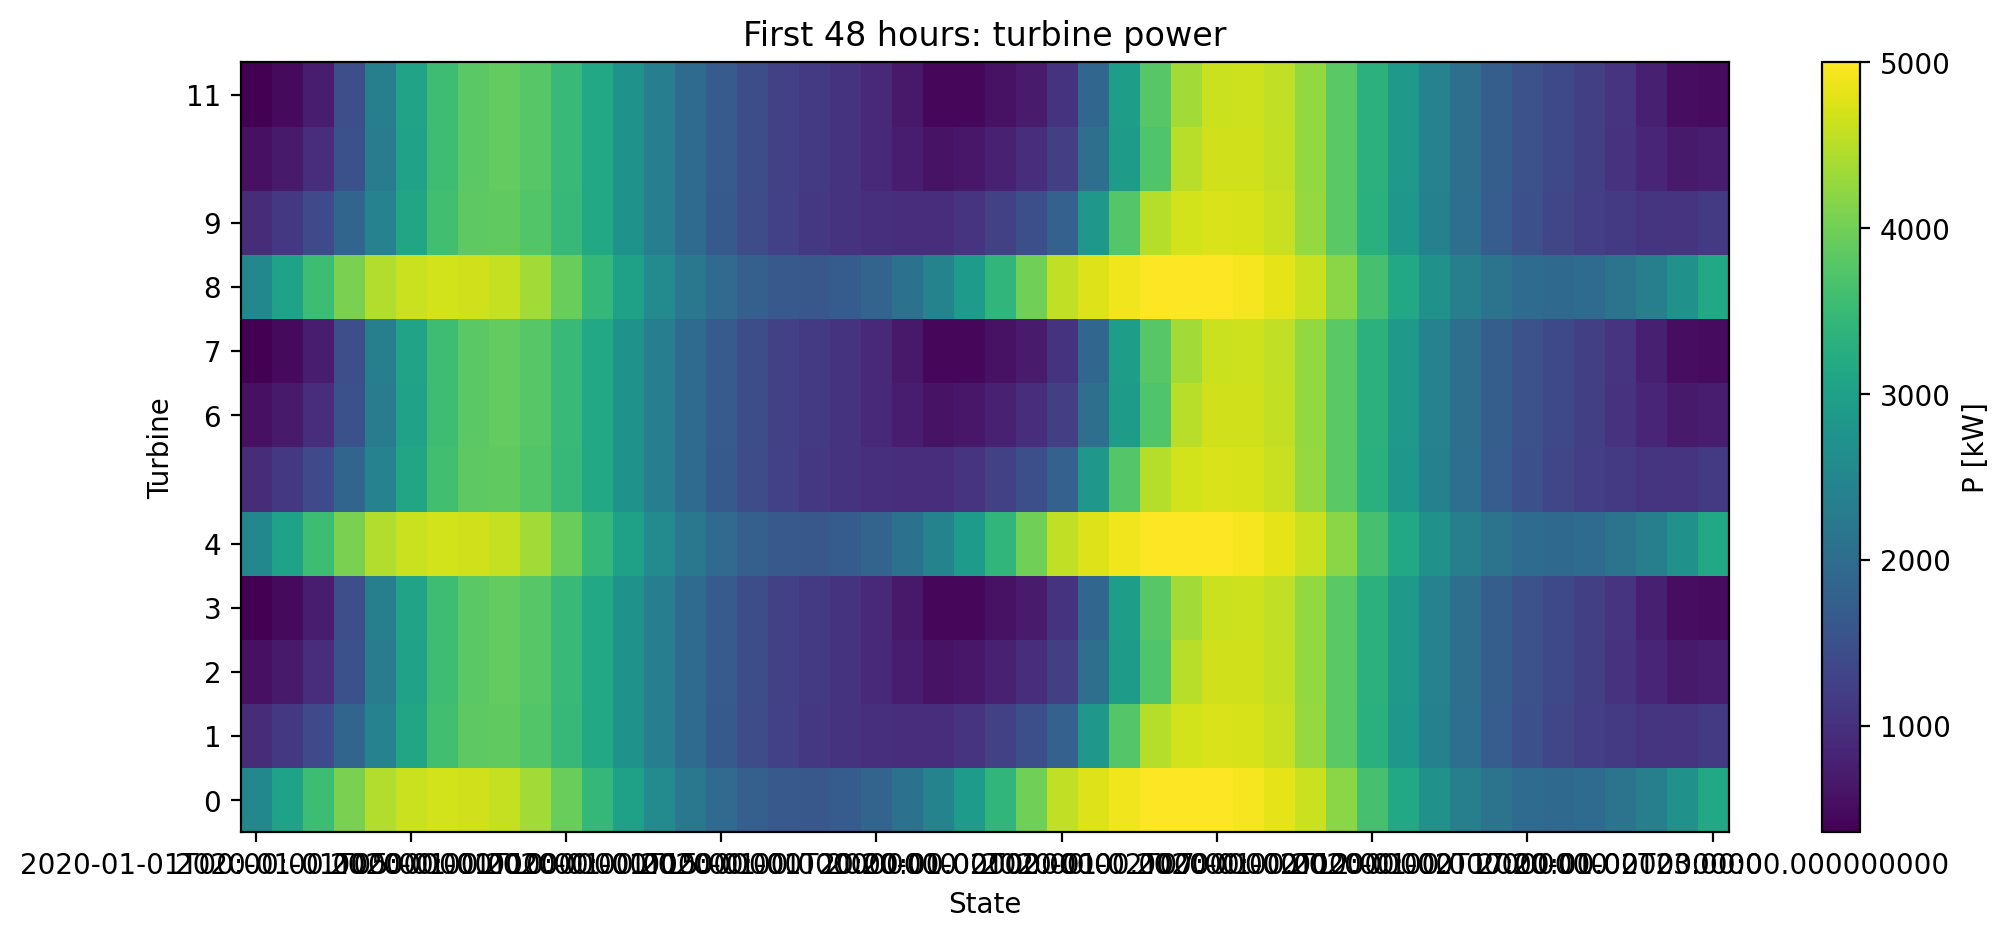

In [19]:
with engine:
    turbine_table = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=list(weather.index[:24]),
        outputs=outputs.StateTurbineTable(
            variables=[FV.P, FV.EFF],
            name_map={FC.STATE: "time", FV.P: "power_kW"},
            isel={FC.TURBINE: slice(0, 4)},
        ),
    )
    power_map = algo.calc_outputs(
        farm_results=farm_results,
        states_sel=list(weather.index[:48]),
        outputs=outputs.StateTurbineMap(
            variable=FV.P,
            plot_pars={"figsize": (12, 5), "title": "First 48 hours: turbine power"},
        ),
    )
display(turbine_table.to_dataframe().head(8))
assert turbine_table.sizes["time"] == 24
assert turbine_table.sizes[FC.TURBINE] == 4
plt.show()
plt.close("all")

### Inspect initialized quadrature with `RotorPointPlot`

The main case uses a centre-point rotor model for a bounded tutorial.
This explicit auxiliary algorithm uses `grid16`, so the figure shows
its 16-point rotor design and weights. No farm results are needed:
the output reads initialized rotor metadata through the metadata-only
lifecycle, without dispatching scientific or output-worker chunks.


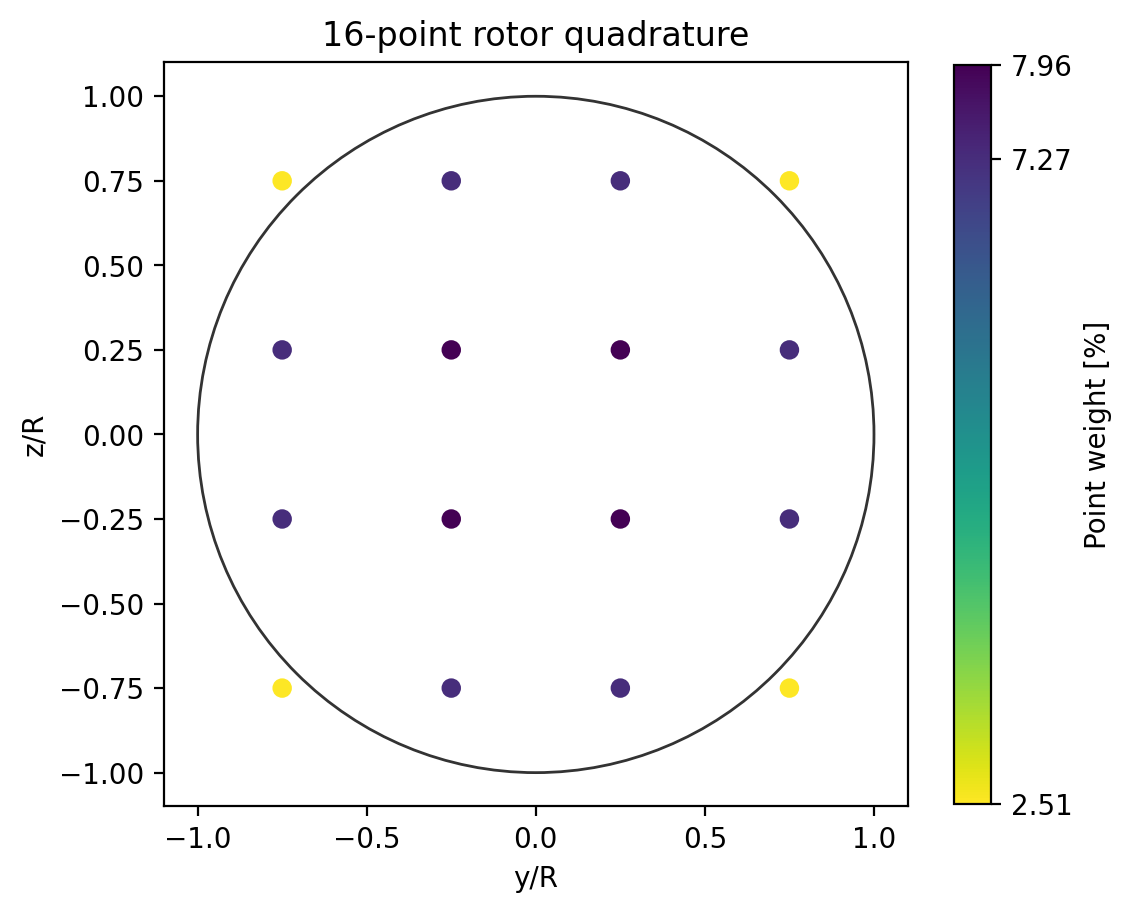

In [20]:
rotor_states = foxes.input.states.StatesTable(
    weather.iloc[:1],
    output_vars=[FV.WS, FV.WD, FV.TI, FV.RHO],
    fixed_vars={FV.TI: 0.08, FV.RHO: 1.225},
)
rotor_algo = foxes.algorithms.Downwind(
    farm, rotor_states, wake_models=[], rotor_model="grid16", verbosity=0
)
with engine:
    rotor_plot = rotor_algo.calc_outputs(
        outputs=outputs.RotorPointPlot(
            plot_pars={"figsize": (6, 6), "title": "16-point rotor quadrature"}
        ),
    )
plt.show()
plt.close("all")

### Explicit curve scans with `TurbineTypeCurves`

A curve output does not create a hidden scan. Configure a separate,
no-wake algorithm with wind speeds from 0 to 25 m/s, then run that
algorithm with `TurbineTypeCurves`. We select one turbine for the
figure because all 12 use the same public NREL 5 MW curve.


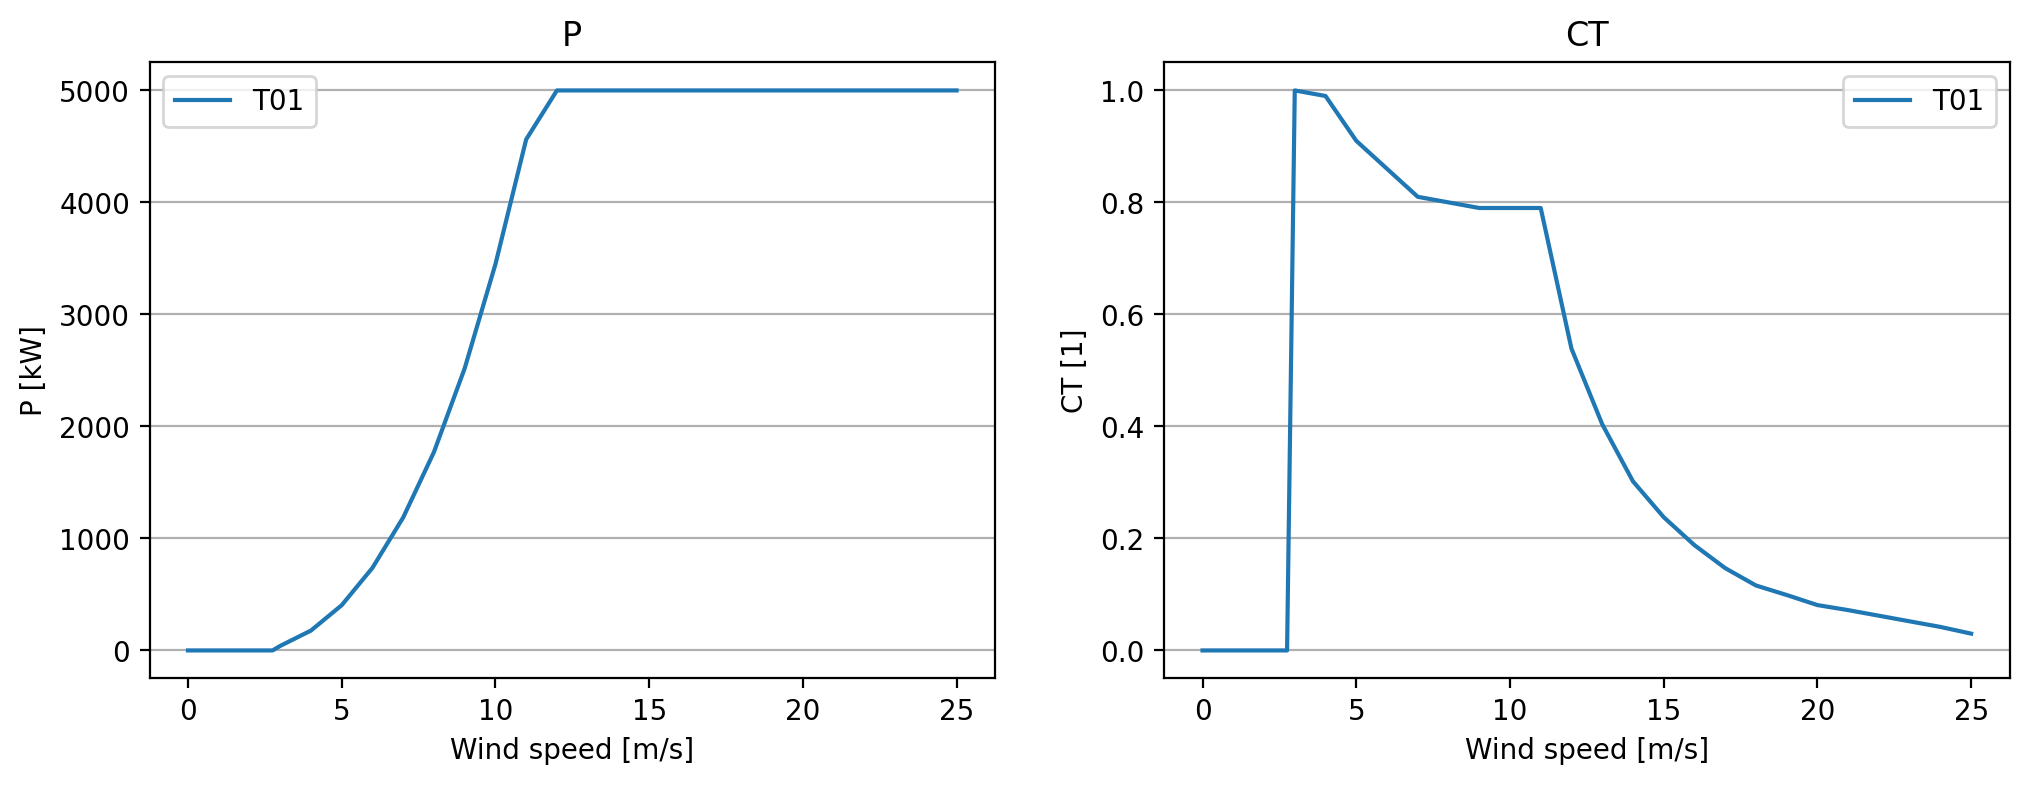

In [21]:
scan_states = foxes.input.states.ScanStates(
    scans={FV.WS: np.linspace(0.0, 25.0, 101)},
    fixed_vars={FV.WD: 270.0, FV.TI: 0.08, FV.RHO: 1.225},
)
curve_algo = foxes.algorithms.Downwind(farm, scan_states, wake_models=[], verbosity=0)
with engine:
    curve_axes = curve_algo.calc_farm(
        outputs=outputs.TurbineTypeCurves(
            isel={FC.TURBINE: [0]},
            plot_pars={"figsize": (12, 4)},
        )
    )
assert len(curve_axes) == 2
plt.show()
plt.close("all")

## 8. Every farm and point writer policy

| Policy | Farm class | Point class | File boundaries |
| --- | --- | --- | --- |
| Count | `FarmResultsCountWriter` | `PointResultsCountWriter` | Exact state count, independent of engine chunks |
| Calendar | `FarmResultsPeriodWriter` | `PointResultsPeriodWriter` | `day`, `week`, `month` or `year`; datetime states required |
| Chunk | `FarmResultsChunkWriter` | `PointResultsChunkWriter` | Farm state chunks; point state/target tiles |

The following **six explicit output instances** exercise every writer class.
They reuse the first 72 hours of already calculated farm and point results.
Count files contain at most 25 timestamps; daily files span 24 hourly samples.
A dedicated, bounded engine uses 32-state/32-point chunks so chunk filenames
visibly differ from count and calendar boundaries.

Writer-only selections return no collected dataset. For production, select
writers directly in `calc_farm` or `calc_points` to avoid retaining full
results. Compose a results class only when a dataset is also needed.
Point count/calendar writers assemble point tiles before writing; point
chunk writers retain target tiling. Public point datasets use `point`;
written point files expose `target` and `target_point`.

Replace the temporary directory with your own destination to keep files.
Distinct stems prevent the six policies from overwriting one another.


In [22]:
writer_states = list(weather.index[:72])
writer_engine = foxes.Engine.new(
    "numpy", n_procs=1, chunk_size_states=32, chunk_size_points=32, verbosity=0
)
with TemporaryDirectory(prefix="foxes-output-tour-") as directory:
    destination = Path(directory)
    writer_models = [
        outputs.FarmResultsCountWriter(
            base_name=destination / "farm_count", n_states_per_file=25, variables=[FV.P]
        ),
        outputs.FarmResultsPeriodWriter(
            base_name=destination / "farm_day", period="day", variables=[FV.P]
        ),
        outputs.FarmResultsChunkWriter(
            base_name=destination / "farm_chunk", variables=[FV.P]
        ),
        outputs.PointResultsCountWriter(
            base_name=destination / "point_count",
            n_states_per_file=25,
            variables=[FV.WS],
        ),
        outputs.PointResultsPeriodWriter(
            base_name=destination / "point_day", period="day", variables=[FV.WS]
        ),
        outputs.PointResultsChunkWriter(
            base_name=destination / "point_chunk", variables=[FV.WS]
        ),
    ]
    with writer_engine:
        written = algo.calc_outputs(
            farm_results=farm_results,
            point_results=point_results,
            states_sel=writer_states,
            outputs=writer_models,
            ret_dict=True,
        )
    file_summary = []
    for filename in sorted(destination.glob("*.nc")):
        with xr.open_dataset(filename) as data:
            file_summary.append({"file": filename.name, **dict(data.sizes)})
    display(pd.DataFrame(file_summary).set_index("file"))
    assert written == {}
    assert len(list(destination.glob("farm_count_*.nc"))) == 3
    assert len(list(destination.glob("point_count_*.nc"))) == 3
    assert len(list(destination.glob("farm_day_*.nc"))) == 3
    assert len(list(destination.glob("point_day_*.nc"))) == 3
    assert len(list(destination.glob("farm_chunk_*.nc"))) == 3
    assert len(list(destination.glob("point_chunk_*.nc"))) == 9

,state,turbine,target,target_point
file,,,,
farm_chunk_000000.nc,24,12.0,NaN,NaN
farm_chunk_000001.nc,24,12.0,NaN,NaN
farm_chunk_000002.nc,24,12.0,NaN,NaN
farm_count_000000.nc,25,12.0,NaN,NaN
farm_count_000001.nc,25,12.0,NaN,NaN
farm_count_000002.nc,22,12.0,NaN,NaN
farm_day_2020-01-01.nc,24,12.0,NaN,NaN
farm_day_2020-01-02.nc,24,12.0,NaN,NaN
farm_day_2020-01-03.nc,24,12.0,NaN,NaN


## 9. Flow animations, turbine traces and the `Animator` helper

`FlowAnimation` writes flow frames; `FlowTurbineAnimation` adds synchronized
turbine traces. Both examples retain the **240 x 160 flow grid**, use
**12 x 7 inch figures**, and select four explicit hourly timestamps at
the algorithm entry point. They are snapshots from the large case, not
frames for all 2,400 timestamps.

GIF encoding uses Pillow; MP4 additionally needs external ffmpeg.
`base_name="wake.gif"` produces **`wake_WS.gif`** because the variable name
is appended. Animation outputs write files rather than returning datasets.
Verbosity 0 is silent, 1 announces creation, 2 adds file/completion details,
and 3 reports individual frames.


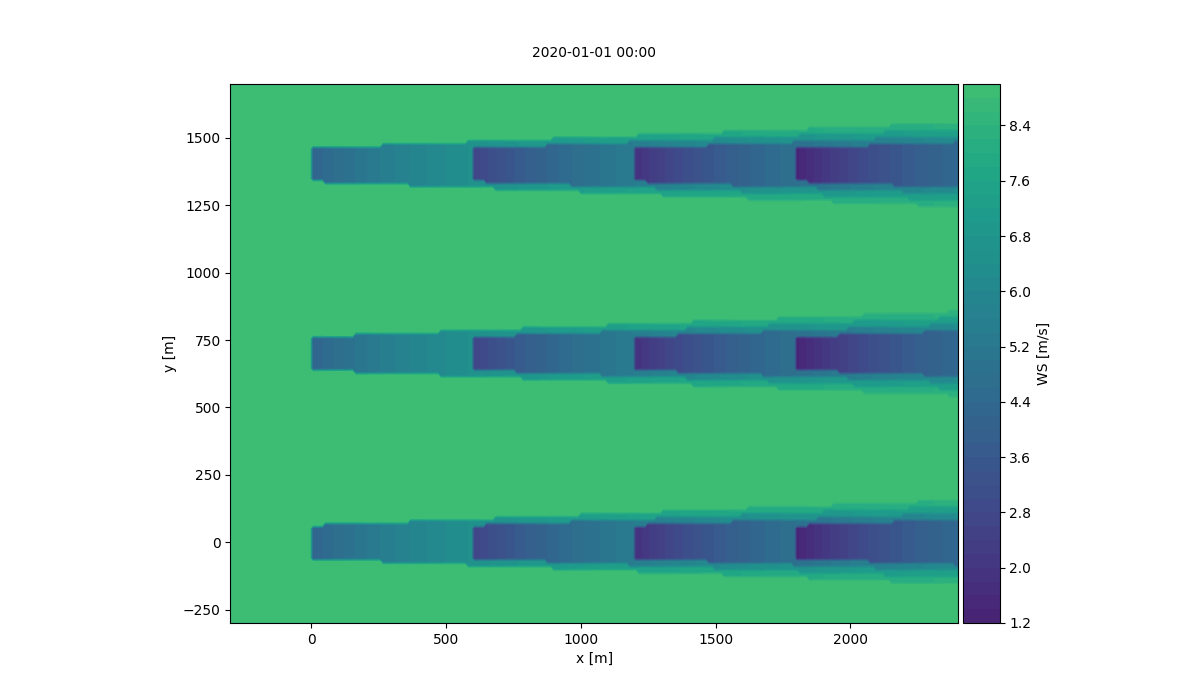

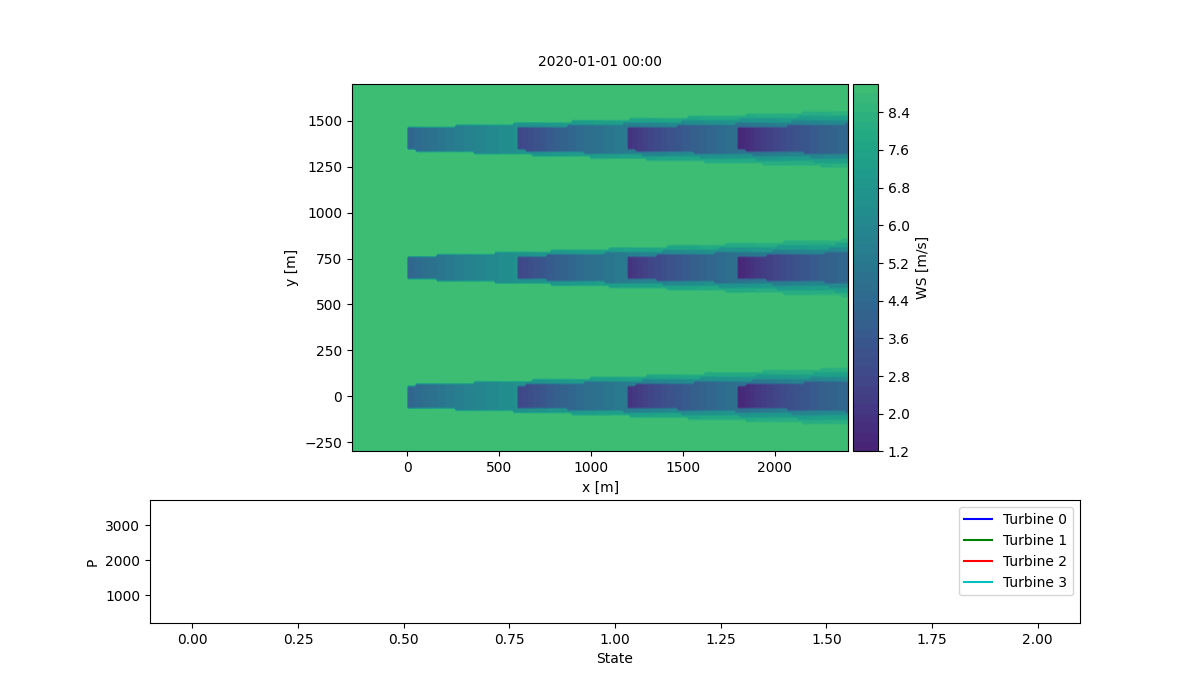

In [23]:
with TemporaryDirectory(prefix="foxes-output-animation-") as directory:
    animation_models = [
        outputs.FlowAnimation(
            out_dir=directory,
            base_name="wake.gif",
            variables=[FV.WS],
            plane="xy",
            grid_pars=grid,
            plot_pars={"levels": 40, "vmin": 0.0, "vmax": 13.0},
            fps=2,
            figsize=(12, 7),
            verbosity=0,
        ),
        outputs.FlowTurbineAnimation(
            out_dir=directory,
            base_name="wake_with_turbines.gif",
            variables=[FV.WS],
            turbines=[0, 1, 2, 3],
            turbine_variable=FV.P,
            plane="xy",
            grid_pars=grid,
            plot_pars={"levels": 40, "vmin": 0.0, "vmax": 13.0},
            fps=2,
            figsize=(12, 7),
            verbosity=0,
        ),
    ]
    with engine:
        algo.calc_outputs(
            farm_results=farm_results,
            states_sel=animation_states,
            outputs=animation_models,
        )
    for basename in ("wake_WS.gif", "wake_with_turbines_WS.gif"):
        animation_file = Path(directory) / basename
        with PillowImage.open(animation_file) as image:
            assert image.width >= 1000
            assert image.n_frames == len(animation_states)
        display(Image(data=animation_file.read_bytes(), format="gif"))

### Compose existing artist frames with `Animator`

`Animator` is a helper exported alongside the output classes, **not an
`Output` subclass or a model-book selector**. Do not pass it to
`outputs=`. It synchronizes generators of `(figure, artists)` frames.
Here the generator uses already calculated point profiles, so no farm or
point science is rerun. The resulting Matplotlib animation can be saved
with its ordinary `save` method.


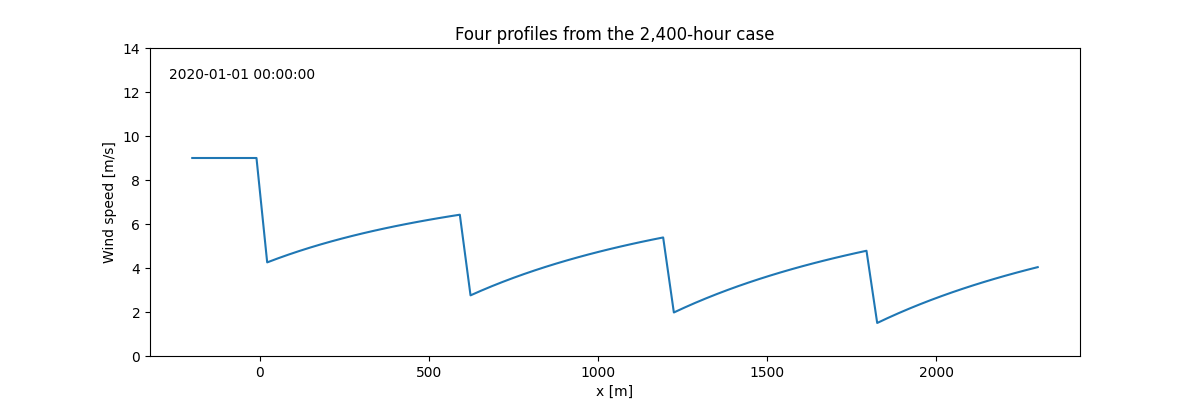

In [24]:
profile_figure, profile_axes = plt.subplots(figsize=(12, 4))
profile_axes.set(
    xlabel="x [m]",
    ylabel="Wind speed [m/s]",
    ylim=(0.0, 14.0),
    title="Four profiles from the 2,400-hour case",
)


def profile_frames():
    for timestamp in animation_states:
        (line,) = profile_axes.plot(
            points[:, 0],
            point_results[FV.WS].sel({FC.STATE: timestamp}),
            color="tab:blue",
            animated=True,
        )
        label = profile_axes.text(
            0.02,
            0.9,
            str(timestamp),
            transform=profile_axes.transAxes,
            animated=True,
        )
        yield profile_figure, [line, label]


animator = outputs.Animator(fig=profile_figure)
animator.add_generator(profile_frames())
profile_animation = animator.animate(verbosity=0, interval=500)
with TemporaryDirectory(prefix="foxes-output-profiles-") as directory:
    profile_file = Path(directory) / "profiles.gif"
    profile_animation.save(profile_file, writer="pillow", fps=2)
    display(Image(data=profile_file.read_bytes(), format="gif"))
plt.close(profile_figure)

## 10. Complete output-class and model-book reference

**The full Markdown table below is generated from a fresh `ModelBook`, so no
registered entry or public output-module class is omitted.** Each row
identifies the class, its model-book entry and the example section above.
`Animator` has an explicit helper row because it has no model-book entry.
The table stays visible when notebook execution outputs are cleared.

A factory template represents every name accepted by that registration,
not just one example. It is impossible to enumerate all concrete names:
counts and chunk indices are unbounded integer parameters. Every
registered factory template is listed, including every filter,
aggregation and writer variant.

| Placeholder | Allowed values / meaning |
| --- | --- |
| `<plane>` | `xy`, `xz`, `yz` |
| `<reduction>` | `states`, `mean` |
| `<period>` | `day`, `week`, `month`, `year` |
| `<n_states_per_file>` | Positive integer; maximum timestamps per count file |
| `<chunk>` | Nonnegative engine state-chunk index |
| `<variables>` for farms | `default`, `calc`, `all`, `P`, `wsP`, `wstiP`, `rhowstiP`, `analysis` |
| `<variables>` for points | `default`, `all` |

The `calc` field set is for standard scientific point inputs, not power
summaries. `all` means every available field, not every possible derived
metric. `analysis` explicitly requests capacity, capacity factors,
efficiency and weights. Default field selections stay unchanged.

Static plotting presets enable `show=True`; animation presets do not.
This tutorial uses configured output instances with `show=False` and
explicit notebook display, rather than opening blocking GUI windows.


| Class name | Model book entry | Entry kind | Runnable example |
| --- | --- | --- | --- |
| `Animator` | `No model-book entry` | Helper | 9: existing artist-frame composition |
| `FarmLayoutOutput` | `farm_layout` | Preset | 4: layout |
| `FarmResultsChunkWriter` | `cluster_results_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_amb_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_amb_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_amb_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_amb_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_waked_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_waked_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_waked_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_waked_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `cluster_results_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_amb_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_amb_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_amb_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_amb_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_waked_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_waked_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_waked_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_waked_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farm_results_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_amb_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_amb_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_amb_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_amb_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_waked_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_waked_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_waked_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_waked_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `farms_results_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_amb_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_amb_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_amb_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_amb_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_waked_<variables>_mean_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_waked_<variables>_write_chunks` | Factory template | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_waked_mean_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_waked_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsChunkWriter` | `total_results_write_chunks` | Preset | 8: engine-chunk files |
| `FarmResultsCountWriter` | `cluster_results_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_amb_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_amb_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_amb_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_amb_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_waked_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_waked_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_waked_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_waked_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `cluster_results_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_amb_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_amb_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_amb_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_amb_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_waked_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_waked_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_waked_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_waked_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farm_results_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_amb_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_amb_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_amb_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_amb_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_waked_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_waked_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_waked_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_waked_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `farms_results_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_amb_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_amb_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_amb_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_amb_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_waked_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_waked_<variables>_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_waked_mean_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_waked_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsCountWriter` | `total_results_write_n<n_states_per_file>` | Factory template | 8: count files |
| `FarmResultsOutput` | `cluster_results` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_amb` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_amb_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_amb_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_amb_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_waked` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_waked_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_waked_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `cluster_results_waked_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_amb` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_amb_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_amb_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_amb_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_waked` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_waked_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_waked_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farm_results_waked_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_amb` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_amb_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_amb_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_amb_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_waked` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_waked_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_waked_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `farms_results_waked_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_amb` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_amb_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_amb_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_amb_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_waked` | Preset | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_waked_<variables>` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_waked_<variables>_mean` | Factory template | 2-3: farm results and aggregation |
| `FarmResultsOutput` | `total_results_waked_mean` | Preset | 2-3: farm results and aggregation |
| `FarmResultsPeriodWriter` | `cluster_results_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_amb_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_amb_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_amb_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_amb_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_waked_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_waked_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_waked_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_waked_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `cluster_results_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_amb_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_amb_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_amb_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_amb_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_waked_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_waked_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_waked_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_waked_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farm_results_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_amb_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_amb_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_amb_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_amb_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_waked_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_waked_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_waked_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_waked_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `farms_results_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_amb_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_amb_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_amb_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_amb_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_waked_<variables>_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_waked_<variables>_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_waked_mean_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_waked_write_<period>` | Factory template | 8: calendar files |
| `FarmResultsPeriodWriter` | `total_results_write_<period>` | Factory template | 8: calendar files |
| `FlowAnimation` | `chunk_gif_<chunk>` | Factory template | 9: flow GIF |
| `FlowAnimation` | `chunk_mp4_<chunk>` | Factory template | 9: flow GIF |
| `FlowAnimation` | `create_gif` | Preset | 9: flow GIF |
| `FlowAnimation` | `create_mp4` | Preset | 9: flow GIF |
| `FlowPlots2D` | `flow_plot` | Preset | 6: high-resolution flow map |
| `FlowPlots2D` | `flow_plot_<plane>_<reduction>` | Factory template | 6: high-resolution flow map |
| `FlowTurbineAnimation` | `create_turbine_gif` | Preset | 9: flow and turbine-trace GIF |
| `FlowTurbineAnimation` | `create_turbine_mp4` | Preset | 9: flow and turbine-trace GIF |
| `PointCalculator` | `point_calculator` | Preset | 5: output-configured probes |
| `PointResultsChunkWriter` | `point_results_<variables>_aggregate_all_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_<variables>_aggregate_all_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_<variables>_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_<variables>_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_aggregate_all_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_aggregate_all_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_<variables>_aggregate_all_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_<variables>_aggregate_all_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_<variables>_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_<variables>_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_aggregate_all_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_aggregate_all_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_amb_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_<variables>_aggregate_all_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_<variables>_aggregate_all_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_<variables>_mean_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_<variables>_write_chunks` | Factory template | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_aggregate_all_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_aggregate_all_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_mean_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_waked_write_chunks` | Preset | 8: point-tile files |
| `PointResultsChunkWriter` | `point_results_write_chunks` | Preset | 8: point-tile files |
| `PointResultsCountWriter` | `point_results_<variables>_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_<variables>_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_<variables>_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_<variables>_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_<variables>_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_<variables>_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_amb_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_<variables>_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_<variables>_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_<variables>_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_<variables>_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_aggregate_all_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_aggregate_all_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_mean_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_waked_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsCountWriter` | `point_results_write_n<n_states_per_file>` | Factory template | 8: point count files |
| `PointResultsOutput` | `point_results` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_<variables>` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_<variables>_aggregate_all` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_<variables>_aggregate_all_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_<variables>_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_aggregate_all` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_aggregate_all_mean` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_<variables>` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_<variables>_aggregate_all` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_<variables>_aggregate_all_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_<variables>_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_aggregate_all` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_aggregate_all_mean` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_amb_mean` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_mean` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_<variables>` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_<variables>_aggregate_all` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_<variables>_aggregate_all_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_<variables>_mean` | Factory template | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_aggregate_all` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_aggregate_all_mean` | Preset | 5: supplied point coordinates |
| `PointResultsOutput` | `point_results_waked_mean` | Preset | 5: supplied point coordinates |
| `PointResultsPeriodWriter` | `point_results_<variables>_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_<variables>_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_<variables>_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_<variables>_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_<variables>_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_<variables>_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_<variables>_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_<variables>_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_amb_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_<variables>_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_<variables>_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_<variables>_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_<variables>_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_aggregate_all_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_aggregate_all_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_mean_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_waked_write_<period>` | Factory template | 8: point calendar files |
| `PointResultsPeriodWriter` | `point_results_write_<period>` | Factory template | 8: point calendar files |
| `RosePlotOutput` | `rose_plot` | Preset | 4: farm wind rose |
| `RotorPointPlot` | `rotor_point_plot` | Preset | 7: initialized rotor design |
| `SliceData` | `slice_data` | Preset | 6: numerical slice |
| `SliceData` | `slice_data_<plane>_<reduction>` | Factory template | 6: numerical slice |
| `SlicesData` | `slices_data` | Preset | 6: multiple parallel planes |
| `SlicesData` | `slices_data_<plane>_<reduction>` | Factory template | 6: multiple parallel planes |
| `StateTurbineMap` | `state_turbine_map` | Preset | 7: turbine power map |
| `StateTurbineTable` | `state_turbine_table` | Preset | 7: selected/renamed table |
| `StatesRosePlotOutput` | `states_rose_plot` | Preset | 4: ambient-location rose |
| `SupportWindRosePlotOutput` | `support_rose_plot` | Preset | 4: native support histograms |
| `TurbineTypeCurves` | `turbine_type_curves` | Preset | 7: explicit curve scan |
| `WindRoseBinPlot` | `wind_rose_bin_plot` | Preset | 4: binned power |


In [ ]:
example_sections = {
    "FarmResultsOutput": "2-3: farm results and aggregation",
    "FarmLayoutOutput": "4: layout",
    "RosePlotOutput": "4: farm wind rose",
    "StatesRosePlotOutput": "4: ambient-location rose",
    "WindRoseBinPlot": "4: binned power",
    "SupportWindRosePlotOutput": "4: native support histograms",
    "PointResultsOutput": "5: supplied point coordinates",
    "PointCalculator": "5: output-configured probes",
    "SliceData": "6: numerical slice",
    "SlicesData": "6: multiple parallel planes",
    "FlowPlots2D": "6: high-resolution flow map",
    "StateTurbineTable": "7: selected/renamed table",
    "StateTurbineMap": "7: turbine power map",
    "RotorPointPlot": "7: initialized rotor design",
    "TurbineTypeCurves": "7: explicit curve scan",
    "FarmResultsCountWriter": "8: count files",
    "FarmResultsPeriodWriter": "8: calendar files",
    "FarmResultsChunkWriter": "8: engine-chunk files",
    "PointResultsCountWriter": "8: point count files",
    "PointResultsPeriodWriter": "8: point calendar files",
    "PointResultsChunkWriter": "8: point-tile files",
    "FlowAnimation": "9: flow GIF",
    "FlowTurbineAnimation": "9: flow and turbine-trace GIF",
    "Animator": "9: existing artist-frame composition",
}
reference_book = foxes.ModelBook()
reference_rows = [
    {
        "Class name": type(model).__name__,
        "Model book entry": name,
        "Entry kind": "Preset",
    }
    for name, model in reference_book.outputs.items()
]
reference_rows.extend(
    {
        "Class name": factory.base.__name__,
        "Model book entry": factory.name_template,
        "Entry kind": "Factory template",
    }
    for factory in reference_book.outputs.factories
)
public_classes = {
    name
    for name, value in vars(outputs).items()
    if not name.startswith("_") and inspect.isclass(value)
}
registered_classes = {row["Class name"] for row in reference_rows}
reference_rows.extend(
    {
        "Class name": name,
        "Model book entry": "No model-book entry",
        "Entry kind": "Helper",
    }
    for name in sorted(public_classes - registered_classes)
)
catalogue = pd.DataFrame(reference_rows).sort_values(
    ["Class name", "Entry kind", "Model book entry"], ignore_index=True
)
catalogue["Runnable example"] = catalogue["Class name"].map(example_sections)
assert set(catalogue["Class name"]) == public_classes
assert catalogue["Runnable example"].notna().all()
display(
    pd.Series(
        {
            "Public classes with examples": len(public_classes),
            "Registered presets": len(reference_book.outputs),
            "Registered factory templates": len(reference_book.outputs.factories),
        }
    )
)

## Choose your own recipe

1. **Pick the entry point:** `calc_farm` for new farm physics, `calc_points`
   for caller-supplied locations, and `calc_outputs` for output-oriented work
   with explicit awareness of any missing scientific inputs.
2. **Ask for metrics:** configure `FarmResultsOutput(variables=[...])`;
   derived performance evaluation is automatic during new farm calculations.
3. **Reduce at the output:** configure state and spatial aggregation rather
   than averaging power ratios or wind directions naively.
4. **Reuse supplied datasets:** `farm_results` avoids rerunning turbine
   physics; `point_results` avoids point recalculation. Requesting a new grid
   still requires point evaluation.
5. **Keep the calculation bounded:** the farm example uses 2,400 hours and
   12 turbines, while high-resolution flow plots explicitly select snapshots.
6. **Choose memory or files deliberately:** compose results classes and
   writers only when both are needed, using distinct filenames.
7. **Distinguish field sets:** `default`, `calc`, `all` and `analysis` have
   different purposes; the complete reference above documents every entry.

Continue with [wind roses](wind_rose.ipynb), [time series](timeseries.ipynb),
[dynamic wakes](dyn_wakes.ipynb), or the [model book](model_book.ipynb).
